# 02 · Raw column audit

One question per raw column of `listings.csv.gz`: **can it be a model input, and with what caveat?**
Six project cities, every snapshot that carries a price. Amenities are set aside for now (team decision);
derived features come later. Results go to `docs/eda/` and are summarised in
[`docs/features.md`](../docs/features.md).

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "strfair").is_dir())
sys.path.insert(0, str(REPO_ROOT))
from strfair.data import PROJECT_CITIES, price_coverage, priced_snapshots, load_listings, load_reviews

OUT = REPO_ROOT / "docs" / "eda"; OUT.mkdir(parents=True, exist_ok=True)
CITIES = PROJECT_CITIES
SHORT = {"new-york-city": "NYC", "los-angeles": "LA", "toronto": "Toronto", "san-diego": "San Diego",
         "clark-county-nv": "Las Vegas", "jersey-city": "Jersey City"}
COLOUR = dict(zip(CITIES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]))
mpl.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "axes.grid.axis": "y", "grid.color": "#e1e0d9", "axes.axisbelow": True, "axes.titlelocation": "left",
                     "axes.titleweight": "semibold", "axes.titlesize": 10, "legend.frameon": False, "font.size": 9})
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 120)
save = lambda df, name, index=False: (df.to_csv(OUT / f"{name}.csv", index=index), df)[1]

/opt/homebrew/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


## 1. Which snapshots have a price at all

city,snapshot,listings,priced,priced_share,partial_scrape
new-york-city,2025-12-04,36261,0,0%,False
new-york-city,2026-03-16,35979,21435,60%,False
new-york-city,2026-06-14,30259,21515,71%,False
los-angeles,2025-12-04,45585,0,0%,False
los-angeles,2026-03-16,46088,37178,81%,False
los-angeles,2026-06-15,43751,38186,87%,False
toronto,2025-09-11,21356,15731,74%,False
toronto,2025-12-12,21602,0,0%,False
toronto,2026-03-19,15490,14654,95%,True
toronto,2026-06-15,22198,18277,82%,False


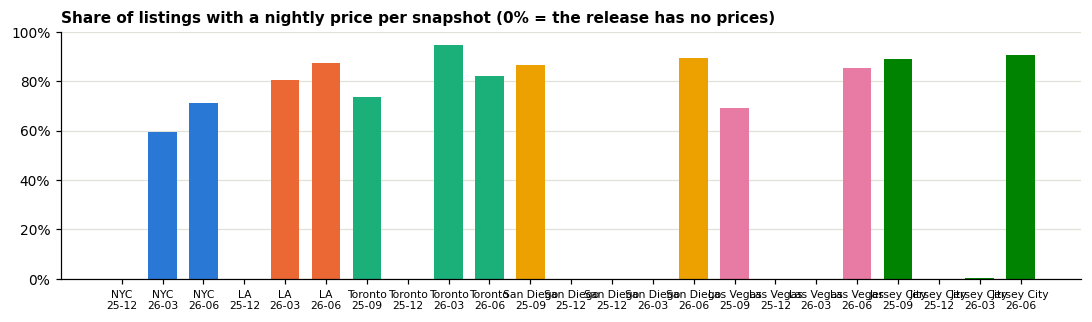

In [2]:
coverage = save(price_coverage(CITIES), "price_coverage")
PRICED = {c: priced_snapshots(c) for c in CITIES}
LATEST = {c: PRICED[c][-1] for c in CITIES}
display(coverage.style.format({"priced_share": "{:.0%}"}).hide(axis="index"))

fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(range(len(coverage)), coverage.priced_share, color=[COLOUR[c] for c in coverage.city], width=0.7)
ax.set_xticks(range(len(coverage))); ax.set_xticklabels([f"{SHORT[c]}\n{s[2:7]}" for c, s in zip(coverage.city, coverage.snapshot)], fontsize=7)
ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0)); ax.set_ylim(0, 1)
ax.set_title("Share of listings with a nightly price per snapshot (0% = the release has no prices)")
plt.tight_layout(); plt.savefig(OUT / "price_coverage.png", bbox_inches="tight"); plt.show()

## 2. Load every priced snapshot; fill rate of every raw column by release

In [3]:
RAW, fills = {}, {}
for city in CITIES:
    for snap in PRICED[city]:
        L = load_listings(city, snap)
        fills[f"{SHORT[city]} {snap}"] = L.drop(columns=["city", "snapshot"]).notna().mean()
        if snap == LATEST[city]:
            RAW[city] = L
FILL = save(pd.DataFrame(fills).round(3), "column_fill_rates", index=True)
c26 = FILL.columns[FILL.columns.str.contains("2026")]
empty_2026 = FILL[c26].max(axis=1).lt(0.01)
partial_2026 = FILL[c26].mean(axis=1).between(0.2, 0.9)
print(f"{len(FILL)} raw columns across {len(fills)} priced snapshots\n")
print("Empty in every 2026 release:", sorted(empty_2026[empty_2026].index), "\n")
print("Partly filled in 2026 (20-90%):"); display(FILL.loc[partial_2026, c26].round(2))

90 raw columns across 13 priced snapshots

Empty in every 2026 release: ['calendar_updated', 'host_acceptance_rate', 'host_neighbourhood', 'host_response_rate', 'host_response_time', 'host_since', 'host_thumbnail_url', 'host_total_listings_count', 'host_verifications', 'instant_bookable', 'neighborhood_overview', 'neighbourhood'] 

Partly filled in 2026 (20-90%):


,NYC 2026-03-16,NYC 2026-06-14,LA 2026-03-16,LA 2026-06-15,Toronto 2026-03-19,Toronto 2026-06-15,San Diego 2026-06-27,Las Vegas 2026-06-27,Jersey City 2026-06-27
bathrooms,0.58,0.67,0.78,0.82,0.39,0.76,0.85,0.80,0.89
bedrooms,0.83,0.64,0.93,0.78,0.81,0.76,0.85,0.84,0.79
beds,0.58,0.69,0.77,0.85,0.39,0.78,0.88,0.84,0.91
estimated_revenue_l365d,0.60,0.71,0.81,0.87,0.95,0.82,0.90,0.85,0.91
first_review,0.69,0.72,0.73,0.74,0.82,0.77,0.83,0.72,0.80
host_about,0.56,0.59,0.56,0.56,0.46,0.46,0.63,0.56,0.60
host_location,0.78,0.76,0.76,0.76,0.70,0.71,0.78,0.72,0.76
last_review,0.69,0.72,0.73,0.74,0.82,0.77,0.83,0.72,0.80
license,0.14,0.18,0.28,0.30,0.60,0.54,0.77,0.35,0.61
neighbourhood_group_cleansed,1.00,1.00,1.00,1.00,0.00,0.00,0.00,0.00,0.00


## 3. The target column: what `price` measures

The per-night rate of one dated quote. Its stay length is the listing's minimum stay, so where regulation
pushes 30-night minimums (NYC) most quotes are monthly rates after a length-of-stay discount.

,city,snapshot,listings,priced,price_median,price_p99,price_max,share_monthly_quote,price_median_monthly,price_median_nightly,lead_days_median,share_quote_eq_min_nights
0,new-york-city,2026-06-14,30259,21515,174.69,1713.935,30972.96,0.768,142.845,308.500,17.0,0.964
1,los-angeles,2026-06-15,43751,38186,223.67,2917.240,20583.33,0.464,137.170,311.150,6.0,0.915
2,toronto,2026-06-15,22198,18277,184.96,1554.786,23611.00,0.535,112.625,319.670,8.0,0.910
3,san-diego,2026-06-27,13225,11856,322.92,2466.752,82340.82,0.265,146.845,406.415,12.0,0.858
4,clark-county-nv,2026-06-27,20234,17271,234.00,1850.520,114163.67,0.194,92.985,269.000,1.0,0.930
5,jersey-city,2026-06-27,2320,2103,235.00,1405.280,6932.00,0.369,109.100,316.360,5.0,0.825


,city,sep2025_vs_jun2026_n,median_log_change,share_abs_change_gt20pct
0,toronto,10939,0.165,0.619
1,san-diego,8528,0.509,0.819
2,clark-county-nv,8873,0.321,0.739
3,jersey-city,1201,0.337,0.733


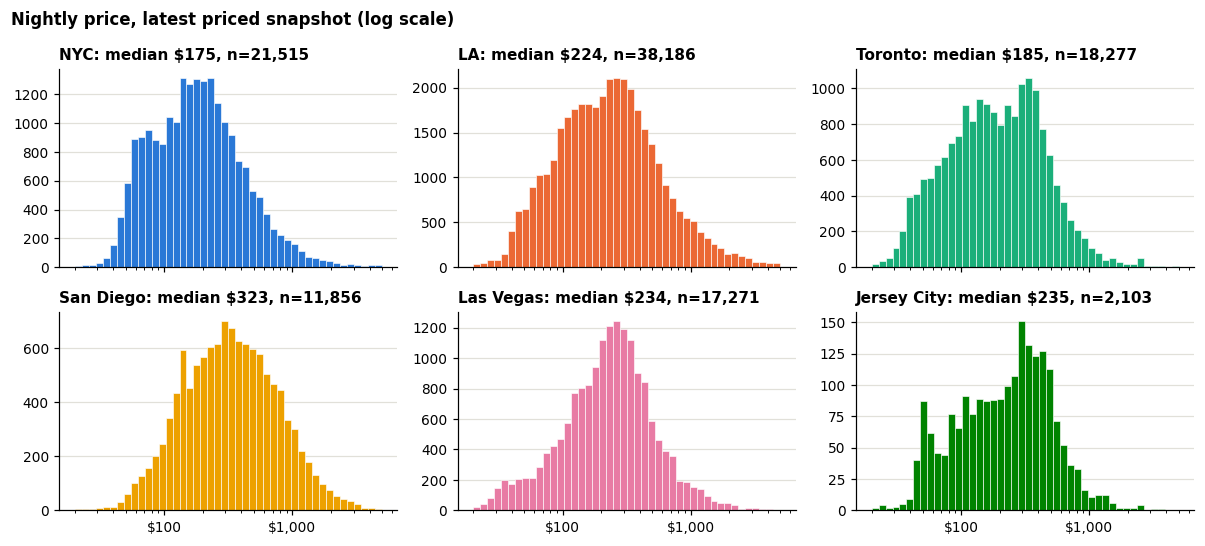

In [4]:
rows = []
for city in CITIES:
    L = RAW[city]; P = L[L.price.notna()]
    nights = (P.price_quote_checkout_date - P.price_quote_checkin_date).dt.days
    lead = (P.price_quote_checkin_date - P.last_scraped).dt.days
    rows.append({"city": city, "snapshot": LATEST[city], "listings": len(L), "priced": len(P),
                 "price_median": P.price.median(), "price_p99": P.price.quantile(.99), "price_max": P.price.max(),
                 "share_monthly_quote": (nights >= 28).mean(), "price_median_monthly": P.price[nights >= 28].median(),
                 "price_median_nightly": P.price[nights < 28].median(), "lead_days_median": lead.median(),
                 "share_quote_eq_min_nights": (nights == P.minimum_nights).mean()})
target = save(pd.DataFrame(rows).round(3), "target_summary"); display(target)

# Sep 2025 vs Jun 2026 for the same listings: the 2025 price has no quote date and is a different measure
rows = []
for city in [c for c in CITIES if PRICED[c][0].startswith("2025")]:
    A = load_listings(city, PRICED[city][0], usecols=["id", "price"]).set_index("id").price.dropna()
    B = RAW[city].set_index("id").price.dropna(); both = A.index.intersection(B.index)
    r = np.log(B[both] / A[both])
    rows.append({"city": city, "sep2025_vs_jun2026_n": len(both), "median_log_change": r.median(), "share_abs_change_gt20pct": (r.abs() > np.log(1.2)).mean()})
display(save(pd.DataFrame(rows).round(3), "price_change_sep2025_jun2026"))

fig, axes = plt.subplots(2, 3, figsize=(11, 5), sharex=True); bins = np.logspace(np.log10(20), np.log10(5000), 45)
for ax, city in zip(axes.flat, CITIES):
    s = RAW[city].price.dropna()
    ax.hist(s.clip(20, 5000), bins=bins, color=COLOUR[city], edgecolor="white", linewidth=0.4); ax.set_xscale("log")
    ax.xaxis.set_major_formatter(mpl.ticker.StrMethodFormatter("${x:,.0f}")); ax.set_title(f"{SHORT[city]}: median ${s.median():,.0f}, n={len(s):,}")
fig.suptitle("Nightly price, latest priced snapshot (log scale)", x=0.01, ha="left", fontweight="semibold")
plt.tight_layout(); plt.savefig(OUT / "price_hist_latest.png", bbox_inches="tight"); plt.show()

## 4. Signal of each raw column against log price

Latest priced snapshot per city, **nightly quotes only** (28+ night quotes would let the monthly discount
masquerade as a column effect). Numeric and boolean columns: Spearman |ρ| with log price. Categorical
columns: √η² (share of log-price variance explained by the category means). Date columns are turned into
"months before the snapshot" (and the quote dates into lead days / nights). Text, URL and id columns are
not scored. Reported as the median and the minimum across the six cities.

In [5]:
CATEGORICAL = ["room_type", "property_type", "neighbourhood_cleansed", "neighbourhood_group_cleansed", "host_response_time", "source"]
DATES = ["host_since", "first_review", "last_review"]
NOT_SCORED = {"id", "listing_url", "scrape_id", "last_scraped", "name", "description", "neighborhood_overview", "picture_url",
              "host_id", "host_url", "host_profile_id", "host_profile_url", "host_name", "host_location", "host_about",
              "host_thumbnail_url", "host_picture_url", "host_neighbourhood", "host_verifications", "neighbourhood",
              "amenities", "bathrooms_text", "license", "calendar_updated", "calendar_last_scraped", "price_quote_raw",
              "price_quote_checkout_date", "price", "price_quote_total_price", "price_quote_price_per_night", "city", "snapshot"}

def eta2(groups, y):
    return ((y.groupby(groups).transform("mean") - y.mean()) ** 2).sum() / ((y - y.mean()) ** 2).sum()

rows = []
for city in CITIES:
    L = RAW[city]; P = L[L.price.notna() & (L.price > 0)].copy()
    P = P[(P.price_quote_checkout_date - P.price_quote_checkin_date).dt.days < 28]
    y = np.log(P.price); snap = pd.Timestamp(LATEST[city])
    for c in DATES:
        P[c] = (snap - P[c]).dt.days / 30.44
    P["price_quote_checkin_date"] = (P.price_quote_checkin_date - P.last_scraped).dt.days   # lead days
    for c in P.columns:
        if c in NOT_SCORED:
            continue
        x = P[c]
        if c in CATEGORICAL:
            x = x.fillna("NA")
            if x.nunique() < 2: continue
            rows.append({"column": c, "city": city, "kind": "categorical", "signal": np.sqrt(eta2(x, y)), "fill": P[c].notna().mean()})
        else:
            if x.dtype == "boolean" or x.dtype == bool: x = x.map({True: 1, False: 0}).astype(float)
            x = pd.to_numeric(x, errors="coerce")
            if x.notna().sum() < 100 or x.nunique() < 2: continue
            rows.append({"column": c, "city": city, "kind": "numeric", "signal": x.corr(y, method="spearman"), "fill": x.notna().mean()})
by_city = pd.DataFrame(rows)
SIGNAL = (by_city.assign(a=by_city.signal.abs()).groupby("column")
          .agg(kind=("kind", "first"), signal_median=("a", "median"), signal_min=("a", "min"), cities=("city", "size"))
          .sort_values("signal_median", ascending=False))
save(by_city.pivot(index="column", columns="city", values="signal").round(3), "column_signal_by_city", index=True)
display(SIGNAL.round(3))

,kind,signal_median,signal_min,cities
column,,,,
accommodates,numeric,0.700,0.570,6
property_type,categorical,0.660,0.517,6
beds,numeric,0.642,0.508,6
bedrooms,numeric,0.620,0.457,6
bathrooms,numeric,0.525,0.374,6
neighbourhood_cleansed,categorical,0.493,0.101,6
room_type,categorical,0.476,0.226,6
calculated_host_listings_count_private_rooms,numeric,0.407,0.094,6
neighbourhood_group_cleansed,categorical,0.327,0.241,2


## 5. Verdict per raw column

Rules, in order: identifiers and free text are not inputs; columns empty in every 2026 release are out;
columns computed from the price (leakage) are out; demand responses (availability, recent review velocity)
are kept for validating the labels, not as inputs; `review_scores_value` is circular (guests rate value
given the price). Everything else is **use**, with a caveat where the fill rate or coverage needs one.

In [6]:
VERDICT = {
    # target and its transforms
    "price": ("target", "per-night rate of one dated quote; clip to $10-$10,000; log"),
    "price_quote_price_per_night": ("target", "identical to price in 2026 releases"),
    "price_quote_total_price": ("no", "price x nights: transform of the target"),
    "price_quote_raw": ("later", "JSON with discount line items; source of an undiscounted-price variant of the target"),
    # quote timing controls
    "price_quote_checkin_date": ("use as control", "lead days = check-in minus scrape date; 2026 releases only"),
    "price_quote_checkout_date": ("use as control", "nights in the quote = checkout minus check-in; 2026 releases only"),
    "minimum_nights": ("use as control", "stay-length rule; equals the quote's length for 83-97% of listings"),
    # leakage / validation
    "estimated_revenue_l365d": ("no", "price x estimated occupancy: leakage"),
    "estimated_occupancy_l365d": ("no", "formula of number_of_reviews_ltm and minimum_nights"),
    "availability_30": ("validation only", "demand response to price (and host blocks)"),
    "availability_60": ("validation only", "same"), "availability_90": ("validation only", "same"),
    "availability_365": ("validation only", "same"), "availability_eoy": ("validation only", "same"),
    "has_availability": ("validation only", "same"),
    "number_of_reviews_ltm": ("validation only", "recent review velocity = cleanest demand proxy"),
    "number_of_reviews_l30d": ("validation only", "same"), "number_of_reviews_ly": ("validation only", "same"),
    "reviews_per_month": ("validation only", "same"),
    "review_scores_value": ("no", "guests rate value given the price: circular"),
    # identifiers / urls / text
    **{c: ("identifier", "") for c in ["id", "listing_url", "scrape_id", "last_scraped", "source", "picture_url", "host_id", "host_url",
                                       "host_profile_id", "host_profile_url", "host_name", "host_thumbnail_url", "host_picture_url",
                                       "calendar_last_scraped", "calendar_updated", "host_verifications"]},
    "name": ("later", "free text: keyword flags / NLP"), "description": ("later", "free text: keyword flags / NLP"),
    "host_about": ("later", "free text; 55% filled"), "host_location": ("later", "free text; 75% filled"),
    "amenities": ("set aside", "JSON list; needs parsing into flags (team decision: later)"),
    "bathrooms_text": ("use", "parse to a number and a shared flag; fills the gaps of bathrooms"),
    "license": ("use with caveat", "non-empty flag; city-specific; in NYC it determines whether a listing can quote nightly"),
    # empty in 2026
    **{c: ("no", "empty in every 2026 release") for c in ["host_since", "host_response_time", "host_response_rate", "host_acceptance_rate",
                                                          "host_total_listings_count", "host_neighbourhood", "instant_bookable",
                                                          "neighbourhood", "neighborhood_overview"]},
    "hosts_time_as_host_years": ("use", "replaces host_since in 2026 releases"), "hosts_time_as_host_months": ("use", "with the years column"),
    "hosts_time_as_user_years": ("optional", "weak"), "hosts_time_as_user_months": ("optional", "weak"),
    # property
    "accommodates": ("use", "strongest single column"), "bedrooms": ("use with caveat", "80% filled in 2026: impute by room type + missing flag"),
    "beds": ("use with caveat", "74% filled: impute + missing flag"), "bathrooms": ("use with caveat", "73% filled; parse bathrooms_text for the rest"),
    "room_type": ("use", "4 levels; fold Hotel/Shared into Private for the interpretable model"),
    "property_type": ("use with caveat", "~70 levels: group into hotel / apartment / house / other"),
    # location
    "neighbourhood_cleansed": ("use with caveat", "97-260 levels in big cities (pool those with <20 listings); only 6-7 levels in Las Vegas and Jersey City"),
    "neighbourhood_group_cleansed": ("use with caveat", "NYC and LA only"),
    "latitude": ("use", "raw for the ensemble; distance-to-centre / spatial lag for the interpretable model"), "longitude": ("use", "same"),
    # host
    "host_is_superhost": ("use", "weak but expected by readers"), "host_listings_count": ("use", "log"),
    "calculated_host_listings_count": ("use", "log; >=5 = multi-listing host"),
    "calculated_host_listings_count_entire_homes": ("use", "share of the host's portfolio"),
    "calculated_host_listings_count_private_rooms": ("use", "same"), "calculated_host_listings_count_shared_rooms": ("optional", "rare"),
    "host_has_profile_pic": ("optional", "weak"), "host_identity_verified": ("optional", "weak"),
    # reviews
    "number_of_reviews": ("use", "log; lifetime track record"), "first_review": ("use", "tenure in months"),
    "last_review": ("use", "months since last review"),
    "review_scores_rating": ("use with caveat", "76% filled: fill + missing flag"), "review_scores_location": ("use with caveat", "76% filled"),
    "review_scores_cleanliness": ("optional", "76% filled, weak"), "review_scores_accuracy": ("optional", "same"),
    "review_scores_checkin": ("optional", "same"), "review_scores_communication": ("optional", "same"),
    # stay rules
    "maximum_nights": ("optional", "weak"), "minimum_minimum_nights": ("optional", "near-duplicate of minimum_nights"),
    "maximum_minimum_nights": ("optional", "same"), "minimum_maximum_nights": ("optional", "weak"), "maximum_maximum_nights": ("optional", "weak"),
    "minimum_nights_avg_ntm": ("optional", "calendar-derived"), "maximum_nights_avg_ntm": ("optional", "calendar-derived"),
}
cols = [c for c in FILL.index]
audit = pd.DataFrame({"column": cols})
audit["verdict"] = audit.column.map(lambda c: VERDICT.get(c, ("?", ""))[0])
audit["note"] = audit.column.map(lambda c: VERDICT.get(c, ("?", ""))[1])
audit["fill_2025"] = audit.column.map(FILL[FILL.columns[~FILL.columns.str.contains("2026")]].mean(axis=1))
audit["fill_2026"] = audit.column.map(FILL[c26].mean(axis=1))
audit = audit.merge(SIGNAL[["kind", "signal_median", "signal_min"]], left_on="column", right_index=True, how="left")
order = ["target", "use", "use as control", "use with caveat", "optional", "validation only", "later", "set aside", "no", "identifier", "?"]
audit["verdict"] = pd.Categorical(audit.verdict, order, ordered=True)
audit = audit.sort_values(["verdict", "signal_median"], ascending=[True, False]).reset_index(drop=True)
save(audit.round(3), "raw_column_audit")
print(audit.verdict.value_counts().reindex(order).dropna().astype(int).to_string())
assert not (audit.verdict == "?").any(), "unclassified columns: " + ", ".join(audit.loc[audit.verdict == "?", "column"])
display(audit[audit.verdict != "identifier"].round(2))

verdict
target              2
use                15
use as control      3
use with caveat     9
optional           16
validation only    10
later               5
set aside           1
no                 13
identifier         16
?                   0


,column,verdict,note,fill_2025,fill_2026,kind,signal_median,signal_min
0,price,target,per-night rate of one dated quote; clip to $10...,0.80,0.82,NaN,NaN,NaN
1,price_quote_price_per_night,target,identical to price in 2026 releases,NaN,0.82,NaN,NaN,NaN
2,accommodates,use,strongest single column,1.00,1.00,numeric,0.70,0.57
3,room_type,use,4 levels; fold Hotel/Shared into Private for t...,1.00,1.00,categorical,0.48,0.23
4,calculated_host_listings_count_private_rooms,use,same,1.00,1.00,numeric,0.41,0.09
5,calculated_host_listings_count_entire_homes,use,share of the host's portfolio,1.00,1.00,numeric,0.31,0.06
6,longitude,use,same,1.00,1.00,numeric,0.21,0.00
7,host_listings_count,use,log,1.00,0.99,numeric,0.20,0.02
8,calculated_host_listings_count,use,log; >=5 = multi-listing host,1.00,1.00,numeric,0.19,0.03
9,latitude,use,raw for the ensemble; distance-to-centre / spa...,1.00,1.00,numeric,0.15,0.03


## 6. The other raw source: review text

In [7]:
rows = []
for city in CITIES:
    rs = load_reviews(city, LATEST[city]); per = rs.groupby("listing_id").size(); n = len(RAW[city])
    com = load_reviews(city, LATEST[city], with_text=True, nrows=40_000).comments.fillna("").astype(str)
    rows.append({"city": city, "reviews": len(rs), "listings_with_any_review": per.size / n, "listings_with_5plus": (per >= 5).sum() / n,
                 "comment_chars_median_sample": com.str.len().median()})
display(save(pd.DataFrame(rows).round(3), "review_text_coverage"))

,city,reviews,listings_with_any_review,listings_with_5plus,comment_chars_median_sample
0,new-york-city,990170,0.725,0.502,273.0
1,los-angeles,1856294,0.746,0.550,228.0
2,toronto,679139,0.773,0.559,210.0
3,san-diego,949213,0.833,0.700,217.0
4,clark-county-nv,726693,0.719,0.511,146.0
5,jersey-city,86754,0.804,0.609,178.0


## Takeaways (full table: `docs/eda/raw_column_audit.csv`; write-up: `docs/features.md`)

- **13 of 25 snapshots carry a price.** `price` is one dated quote's per-night rate; 77% of NYC's quotes
  (54% Toronto, 46% LA) are 28+ night rates after a monthly discount, so keep them with the quote length as
  a control. The Sep 2025 price is a different measure (+17% to +51% for the same listings by Jun 2026).
- **Use (15):** `accommodates`, `room_type`, the host-portfolio counts, coordinates, `number_of_reviews`,
  review dates, superhost, `hosts_time_as_host_*`, `bathrooms_text`. **With a caveat (9):** `property_type`
  (group), `beds` / `bedrooms` / `bathrooms` (impute + flag), `neighbourhood_cleansed` (pool small; useless in
  Las Vegas / Jersey City), `neighbourhood_group_cleansed` (NYC/LA), two review scores (76% filled), `license`.
- **Controls (3):** quote check-in / check-out dates, `minimum_nights`.
- **Not inputs:** availability and recent review counts (validation only); `estimated_revenue_l365d`
  (leakage), `estimated_occupancy_l365d` (formula), `review_scores_value` (circular), quote total; nine
  columns empty in every 2026 release.